# Mini Project: Evaluating Clustering Before and After PCA
## Dataset: Loan data (987,548 loans, 57 columns)

**Objective:** understand how dimensionality reduction (PCA) affects K-Means clustering by comparing the results before and after applying PCA.

The dataset is a custom numerical dataset with many numeric features, so PCA to 2 components is a real reduction.

## 1. Load and explore the data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/loan_processed_data.csv')

Mounted at /content/drive


In [2]:
df.head()

,loan_amnt,term,int_rate,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,...,num_rev_tl_bal_gt_0,num_tl_120dpd_2m,num_tl_30dpd,num_tl_op_past_12m,pct_tl_nvr_dlq,pub_rec_bankruptcies,tax_liens,total_bal_ex_mort,disbursement_method,debt_settlement_flag
0,3600.0,36 months,13.99,C,C4,leadman,10+ years,MORTGAGE,55000.0,Not Verified,...,4.0,0.0,0.0,3.0,76.9,0.0,0.0,7746.0,Cash,N
1,24700.0,36 months,11.99,C,C1,Engineer,10+ years,MORTGAGE,65000.0,Not Verified,...,5.0,0.0,0.0,2.0,97.4,0.0,0.0,39475.0,Cash,N
2,10400.0,60 months,22.45,F,F1,Contract Specialist,3 years,MORTGAGE,104433.0,Source Verified,...,6.0,0.0,0.0,4.0,96.6,0.0,0.0,95768.0,Cash,N
3,20000.0,36 months,9.17,B,B2,Vice President of Recruiting Operations,10+ years,MORTGAGE,180000.0,Not Verified,...,6.0,0.0,0.0,2.0,96.3,0.0,0.0,116762.0,Cash,N
4,20000.0,36 months,8.49,B,B1,road driver,10+ years,MORTGAGE,85000.0,Not Verified,...,2.0,0.0,0.0,0.0,93.3,0.0,0.0,27937.0,Cash,N


In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (987548, 57)


In [4]:
print("Missing Values:", df.isnull().sum().sum())

Missing Values: 0


In [5]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [6]:
print("Data Types:",df.dtypes.value_counts())

Data Types: float64    37
object     20
Name: count, dtype: int64


In [7]:
print('Unique Values:', df.nunique())

Unique Values: loan_amnt                       1545
term                               2
int_rate                         356
grade                              7
sub_grade                         35
emp_title                     291766
emp_length                        11
home_ownership                     6
annual_inc                     45860
verification_status                3
issue_d                           77
loan_status                        2
purpose                           14
title                          31918
zip_code                         938
addr_state                        51
dti                             6303
delinq_2yrs                       30
earliest_cr_line                 717
fico_range_high                   38
inq_last_6mths                     9
open_acc                          81
pub_rec                           36
revol_bal                      74538
revol_util                      1198
total_acc                        140
initial_list_status    

In [8]:
df.describe()

,loan_amnt,int_rate,annual_inc,dti,delinq_2yrs,fico_range_high,inq_last_6mths,open_acc,pub_rec,revol_bal,...,mths_since_recent_inq,num_accts_ever_120_pd,num_rev_tl_bal_gt_0,num_tl_120dpd_2m,num_tl_30dpd,num_tl_op_past_12m,pct_tl_nvr_dlq,pub_rec_bankruptcies,tax_liens,total_bal_ex_mort
count,987548.000000,987548.000000,9.875480e+05,987548.000000,987548.000000,987548.000000,987548.000000,987548.000000,987548.000000,9.875480e+05,...,987548.000000,987548.000000,987548.000000,987548.000000,987548.000000,987548.000000,987548.000000,987548.000000,987548.000000,9.875480e+05
mean,14823.987568,13.374654,7.943767e+04,18.649139,0.329461,699.154277,0.687777,12.156805,0.222393,1.630223e+04,...,6.778074,0.549182,5.677125,0.000812,0.003531,2.306833,94.290564,0.136987,0.055651,5.318275e+04
std,8774.155691,4.818374,7.304026e+04,9.394018,0.890052,31.070245,0.927708,5.539740,0.622113,2.156771e+04,...,5.855609,1.381261,3.213420,0.030445,0.063393,1.847883,8.506546,0.385145,0.417636,4.906838e+04
min,1000.000000,5.310000,0.000000e+00,-1.000000,0.000000,664.000000,0.000000,1.000000,0.000000,0.000000e+00,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.000000,0.000000,0.000000e+00
25%,8000.000000,9.800000,4.950000e+04,12.350000,0.000000,674.000000,0.000000,8.000000,0.000000,6.150000e+03,...,2.000000,0.000000,3.000000,0.000000,0.000000,1.000000,91.700000,0.000000,0.000000,2.367000e+04
50%,12800.000000,12.880000,6.800000e+04,18.040000,0.000000,694.000000,0.000000,11.000000,0.000000,1.137300e+04,...,5.000000,0.000000,5.000000,0.000000,0.000000,2.000000,97.700000,0.000000,0.000000,4.041200e+04
75%,20000.000000,16.200000,9.500000e+04,24.410000,0.000000,714.000000,1.000000,15.000000,0.000000,2.001500e+04,...,10.000000,1.000000,7.000000,0.000000,0.000000,3.000000,100.000000,0.000000,0.000000,6.643000e+04
max,40000.000000,30.990000,1.099920e+07,999.000000,39.000000,850.000000,8.000000,90.000000,86.000000,2.568995e+06,...,24.000000,51.000000,44.000000,6.000000,4.000000,30.000000,100.000000,12.000000,85.000000,3.408095e+06


## 2. Preprocessing
1. **Missing values:** checked above, there are none (and no duplicate rows).
2. **Numeric features only:** K-Means and PCA work with distances/variance, so the 20 text columns are left out (37 numeric columns remain).
3. **Remove leakage columns:** `total_pymnt`, `total_rec_int`, `total_rec_late_fee`, `recoveries`, `last_pymnt_amnt`, `last_fico_range_high` describe what happened *after* the loan was issued, not the borrower profile.
4. **Remove near-empty columns:** 7 columns are more than 96% zeros and carry almost no information for clustering.
5. **Handle extreme values:** values below the 1st and above the 99th percentile are clipped. Rows are kept.
6. **Standardization (required):** every feature gets mean 0 and std 1, so large-scale features do not dominate the distances.

In [9]:
num_cols = df.select_dtypes(include='number').columns.tolist()

In [10]:
leakage_cols = ['total_pymnt', 'total_rec_int', 'total_rec_late_fee',
                'recoveries', 'last_pymnt_amnt', 'last_fico_range_high']
features = [c for c in num_cols if c not in leakage_cols]
X = df[features].copy()

In [11]:
stats = pd.DataFrame({
    'nunique': X.nunique(),
    'std': X.std().round(2),
    'pct_zero': (X == 0).mean().round(3)
}).sort_values('pct_zero', ascending=False)
stats.head(15)

,nunique,std,pct_zero
num_tl_120dpd_2m,6,0.03,0.999
num_tl_30dpd,5,0.06,0.997
delinq_amnt,1608,734.97,0.996
acc_now_delinq,8,0.08,0.995
chargeoff_within_12_mths,10,0.11,0.992
collections_12_mths_ex_med,11,0.14,0.984
tax_liens,34,0.42,0.966
pub_rec_bankruptcies,12,0.39,0.874
tot_coll_amt,11613,12524.81,0.839
pub_rec,36,0.62,0.827


In [12]:
X.describe(percentiles=[.01, .5, .99]).T[['min', '1%', '50%', '99%', 'max']]

,min,1%,50%,99%,max
loan_amnt,1000.00,1650.00,12800.00,35000.00,40000.00
int_rate,5.31,5.32,12.88,26.77,30.99
annual_inc,0.00,22000.00,68000.00,262521.20,10999200.00
dti,-1.00,2.29,18.04,38.44,999.00
delinq_2yrs,0.00,0.00,0.00,4.00,39.00
fico_range_high,664.00,664.00,694.00,804.00,850.00
inq_last_6mths,0.00,0.00,0.00,4.00,8.00
open_acc,1.00,4.00,11.00,30.00,90.00
pub_rec,0.00,0.00,0.00,3.00,86.00
revol_bal,0.00,283.00,11373.00,89996.54,2568995.00


In [13]:
near_empty = ['num_tl_120dpd_2m', 'num_tl_30dpd', 'delinq_amnt', 'acc_now_delinq',
              'chargeoff_within_12_mths', 'collections_12_mths_ex_med', 'tax_liens']

X = X.drop(columns=near_empty)
print(X.shape)

(987548, 24)


In [14]:
lower = X.quantile(0.01)
upper = X.quantile(0.99)
X_clipped = X.clip(lower=lower, upper=upper, axis=1)

X_clipped.describe().T[['min', 'max']].join(X[['dti', 'annual_inc']].describe().T[['min', 'max']], rsuffix='_before')

,min,max,min_before,max_before
loan_amnt,1650.00,35000.00,NaN,NaN
int_rate,5.32,26.77,NaN,NaN
annual_inc,22000.00,262521.20,0.0,10999200.0
dti,2.29,38.44,-1.0,999.0
delinq_2yrs,0.00,4.00,NaN,NaN
fico_range_high,664.00,804.00,NaN,NaN
inq_last_6mths,0.00,4.00,NaN,NaN
open_acc,4.00,30.00,NaN,NaN
pub_rec,0.00,3.00,NaN,NaN
revol_bal,283.00,89996.54,NaN,NaN


In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clipped)

print(X_scaled.shape)
print("mean:", X_scaled.mean(axis=0).round(2).max())
print("std :", X_scaled.std(axis=0).round(2).min(), "-", X_scaled.std(axis=0).round(2).max())

(987548, 24)
mean: -0.0
std : 1.0 - 1.0


## 3. Choosing the number of clusters (k)
K-Means needs k in advance. We try k = 2 to 10 using the elbow method (inertia) and the silhouette score. For speed, this search uses a random sample of 50,000 rows.

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rng = np.random.RandomState(42)
idx = rng.choice(len(X_scaled), 50000, replace=False)
X_sample = X_scaled[idx]

K_range = range(2, 11)
inertias, sils = [], []

for k in K_range:
    km = KMeans(n_clusters=k, n_init=3, random_state=42).fit(X_sample)
    inertias.append(km.inertia_)
    s = silhouette_score(X_sample, km.labels_, sample_size=10000, random_state=42)
    sils.append(s)
    print(f"k={k}  inertia={km.inertia_:,.0f}  silhouette={s:.3f}")

k=2  inertia=1,066,389  silhouette=0.136
k=3  inertia=991,097  silhouette=0.133
k=4  inertia=933,737  silhouette=0.125
k=5  inertia=887,907  silhouette=0.116
k=6  inertia=845,556  silhouette=0.107
k=7  inertia=821,816  silhouette=0.081
k=8  inertia=788,672  silhouette=0.073
k=9  inertia=768,696  silhouette=0.070
k=10  inertia=752,684  silhouette=0.083


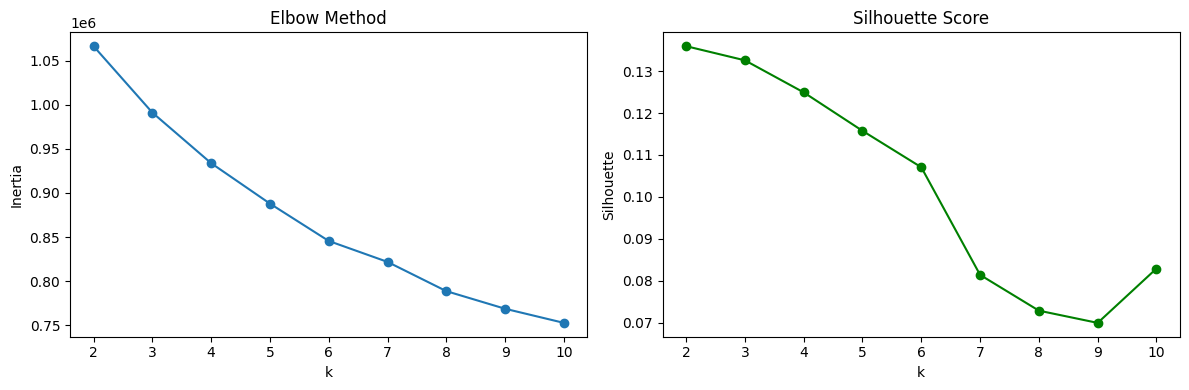

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(K_range, inertias, marker='o')
ax[0].set_title('Elbow Method')
ax[0].set_xlabel('k'); ax[0].set_ylabel('Inertia')

ax[1].plot(K_range, sils, marker='o', color='green')
ax[1].set_title('Silhouette Score')
ax[1].set_xlabel('k'); ax[1].set_ylabel('Silhouette')

plt.tight_layout()
plt.show()

## 4. K-Means before PCA
We use **k = 3** (silhouette for k = 3 is almost the same as k = 2, and k = 3 gives more detail). The same k is used after PCA so the comparison is fair.

The `evaluate` function records three internal metrics (Silhouette: higher is better, Davies-Bouldin: lower is better, Calinski-Harabasz: higher is better). Silhouette uses a fixed 10,000-row sample because it is slow on ~1M rows.

In [18]:
import time
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

# The same evaluation sample is always used so the comparison is fair
eval_idx = np.random.RandomState(0).choice(len(X_scaled), 10000, replace=False)

def evaluate(X_data, labels, name):
    return {
        'Method': name,
        'Silhouette': silhouette_score(X_data[eval_idx], labels[eval_idx]),
        'Davies-Bouldin': davies_bouldin_score(X_data, labels),
        'Calinski-Harabasz': calinski_harabasz_score(X_data, labels),
    }

In [19]:
K = 3

t0 = time.time()
km_before = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_scaled)
time_before = time.time() - t0
labels_before = km_before.labels_

print(f"Time: {time_before:.1f}s")
print(pd.Series(labels_before).value_counts().sort_index())

res_before = evaluate(X_scaled, labels_before, 'KMeans (24 features)')
res_before

Time: 29.6s
0    134587
1    303214
2    549747
Name: count, dtype: int64


{'Method': 'KMeans (24 features)',
 'Silhouette': np.float64(0.13433038987173943),
 'Davies-Bouldin': np.float64(2.3737488395987505),
 'Calinski-Harabasz': np.float64(103296.12634177478)}

Average feature values per cluster (to understand what each cluster represents):

In [20]:
profile = X_clipped.assign(cluster=labels_before).groupby('cluster').mean().round(1)
profile.T

cluster,0,1,2
loan_amnt,12494.1,19919.3,12532.4
int_rate,14.1,13.0,13.4
annual_inc,69984.9,106899.1,63639.6
dti,17.5,20.5,17.8
delinq_2yrs,0.2,0.3,0.3
fico_range_high,682.7,707.5,698.4
inq_last_6mths,0.8,0.8,0.6
open_acc,11.5,16.6,9.8
pub_rec,1.3,0.1,0.0
revol_bal,8896.1,26805.2,11067.5


## 5. PCA with 2 components
PCA builds new axes that capture as much variance as possible. We keep 2 components and check how much variance they keep, which features they are made of, and how many components would be needed for 90% of the variance.

In [21]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance per PC:", pca.explained_variance_ratio_.round(3))
print("Total explained by 2 PCs :", pca.explained_variance_ratio_.sum().round(3))
print("Information lost         :", (1 - pca.explained_variance_ratio_.sum()).round(3))

Explained variance per PC: [0.172 0.118]
Total explained by 2 PCs : 0.29
Information lost         : 0.71


In [22]:
loadings = pd.DataFrame(pca.components_.T, index=X_clipped.columns, columns=['PC1', 'PC2'])

print("PC1 top features:")
print(loadings['PC1'].abs().sort_values(ascending=False).head(6).index.tolist())
print("PC2 top features:")
print(loadings['PC2'].abs().sort_values(ascending=False).head(6).index.tolist())

loadings.round(2)

PC1 top features:
['open_acc', 'total_acc', 'total_bal_ex_mort', 'tot_cur_bal', 'revol_bal', 'annual_inc']
PC2 top features:
['num_tl_op_past_12m', 'acc_open_past_24mths', 'fico_range_high', 'int_rate', 'inq_last_6mths', 'mths_since_recent_inq']


,PC1,PC2
loan_amnt,0.23,-0.16
int_rate,-0.01,0.29
annual_inc,0.28,-0.17
dti,0.11,0.11
delinq_2yrs,0.00,0.07
fico_range_high,0.09,-0.34
inq_last_6mths,0.09,0.27
open_acc,0.37,0.15
pub_rec,-0.06,0.23
revol_bal,0.30,-0.18


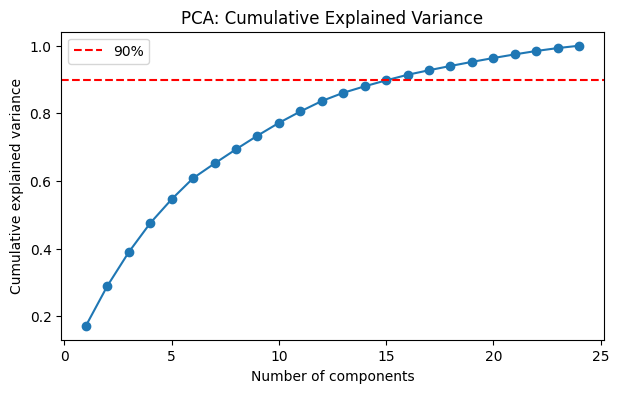

Components for 90% variance: 16


In [23]:
pca_full = PCA().fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 25), cum_var, marker='o')
plt.axhline(0.90, color='red', linestyle='--', label='90%')
plt.xlabel('Number of components'); plt.ylabel('Cumulative explained variance')
plt.title('PCA: Cumulative Explained Variance')
plt.legend(); plt.show()

print("Components for 90% variance:", np.argmax(cum_var >= 0.90) + 1)

## 6. K-Means after PCA
Same k = 3 and same settings, applied to the 2 PCA components. We then compare with the results before PCA. Since silhouette values in 2D and in 24D are not directly comparable, the after-PCA clusters are also evaluated in the original 24-feature space.

In [24]:
t0 = time.time()
km_after = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_pca)
time_after = time.time() - t0
labels_after = km_after.labels_

print(f"Time: {time_after:.1f}s")
print(pd.Series(labels_after).value_counts().sort_index())

res_after = evaluate(X_pca, labels_after, 'KMeans (2 PCs)')
res_after

Time: 6.5s
0    229710
1    478886
2    278952
Name: count, dtype: int64


{'Method': 'KMeans (2 PCs)',
 'Silhouette': np.float64(0.3606830919788712),
 'Davies-Bouldin': np.float64(0.9467668439718707),
 'Calinski-Harabasz': np.float64(636091.9231182751)}

In [25]:
# Also evaluate the after-PCA clusters in the original 24-feature space (fair comparison)
res_after_orig = evaluate(X_scaled, labels_after, 'KMeans (2 PCs) - judged in 24D')

comparison = pd.DataFrame([res_before, res_after, res_after_orig]).set_index('Method')
comparison['Time (s)'] = [time_before, time_after, time_after]
comparison.round(4)

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Time (s)
Method,,,,
KMeans (24 features),0.1343,2.3737,103296.1263,29.5585
KMeans (2 PCs),0.3607,0.9468,636091.9231,6.4869
KMeans (2 PCs) - judged in 24D,0.1079,2.7284,96901.0464,6.4869


In [26]:
ari_between = adjusted_rand_score(labels_before, labels_after)
print("ARI between before-PCA and after-PCA clusters:", round(ari_between, 3))
pd.crosstab(labels_before, labels_after, rownames=['Before'], colnames=['After'])

ARI between before-PCA and after-PCA clusters: 0.457


After,0,1,2
Before,,,
0,2107,51209,81271
1,216971,120,86123
2,10632,427557,111558


## 7. Visualization: before vs after PCA

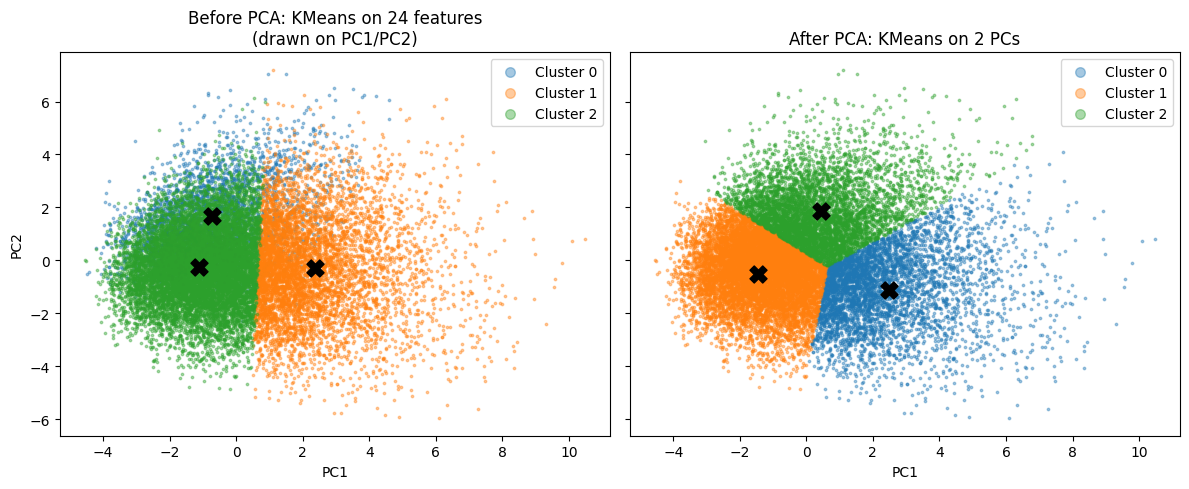

In [27]:
viz_idx = np.random.RandomState(1).choice(len(X_pca), 20000, replace=False)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

cent_before = pca.transform(km_before.cluster_centers_)   # centroids of the original clustering projected onto PC1/PC2
cent_after = km_after.cluster_centers_

fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

# 1) K-Means on 24 features, drawn on PC1/PC2
for c in range(K):
    m = labels_before[viz_idx] == c
    ax[0].scatter(X_pca[viz_idx][m, 0], X_pca[viz_idx][m, 1], s=3, alpha=0.4, color=colors[c], label=f'Cluster {c}')
ax[0].scatter(cent_before[:, 0], cent_before[:, 1], c='black', marker='X', s=150)
ax[0].set_title('Before PCA: KMeans on 24 features\n(drawn on PC1/PC2)')

# 2) K-Means after PCA
for c in range(K):
    m = labels_after[viz_idx] == c
    ax[1].scatter(X_pca[viz_idx][m, 0], X_pca[viz_idx][m, 1], s=3, alpha=0.4, color=colors[c], label=f'Cluster {c}')
ax[1].scatter(cent_after[:, 0], cent_after[:, 1], c='black', marker='X', s=150)
ax[1].set_title('After PCA: KMeans on 2 PCs')

for a in ax:
    a.set_xlabel('PC1'); a.legend(markerscale=4)
ax[0].set_ylabel('PC2')
plt.tight_layout(); plt.show()

In [28]:
profile_after = X_clipped.assign(cluster=labels_after).groupby('cluster').mean().round(1)
profile_after.T

cluster,0,1,2
loan_amnt,21542.0,12455.8,13255.5
int_rate,11.7,12.7,15.7
annual_inc,117035.5,63537.6,69928.0
dti,19.6,16.8,20.7
delinq_2yrs,0.3,0.3,0.4
fico_range_high,715.9,699.8,683.9
inq_last_6mths,0.6,0.4,1.2
open_acc,15.9,9.0,14.4
pub_rec,0.0,0.2,0.4
revol_bal,30331.0,10648.9,11982.0


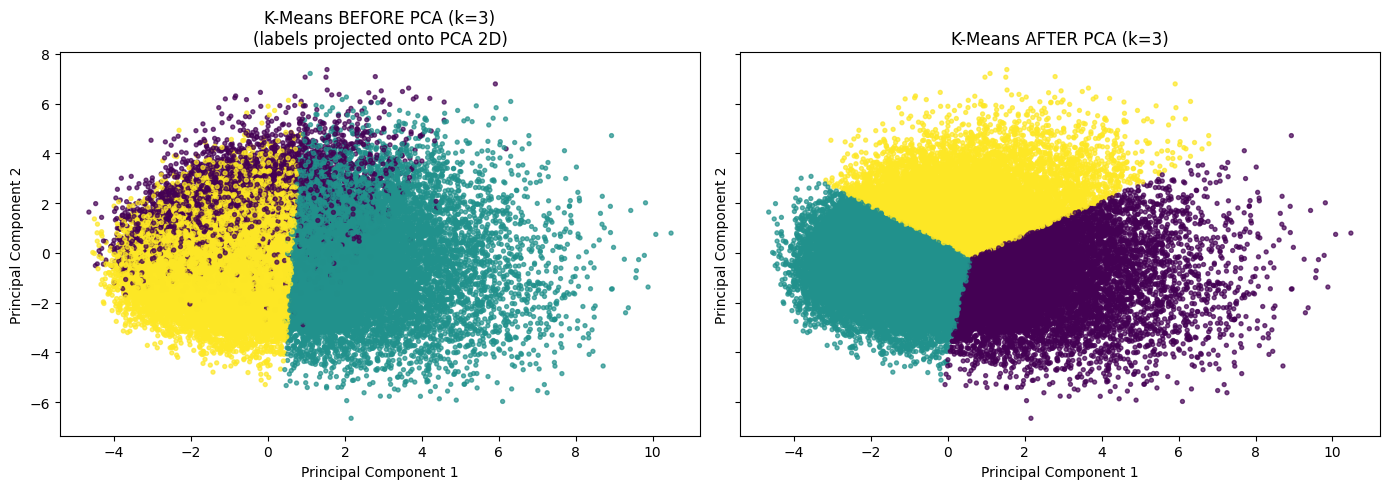

In [29]:
viz_idx = np.random.RandomState(1).choice(len(X_pca), 50000, replace=False)

def plot_compare(lab_before, lab_after, k):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

    ax[0].scatter(X_pca[viz_idx, 0], X_pca[viz_idx, 1],
                  c=lab_before[viz_idx], cmap='viridis', s=8, alpha=0.7)
    ax[0].set_title(f'K-Means BEFORE PCA (k={k})\n(labels projected onto PCA 2D)')

    ax[1].scatter(X_pca[viz_idx, 0], X_pca[viz_idx, 1],
                  c=lab_after[viz_idx], cmap='viridis', s=8, alpha=0.7)
    ax[1].set_title(f'K-Means AFTER PCA (k={k})')

    for a in ax:
        a.set_xlabel('Principal Component 1')
        a.set_ylabel('Principal Component 2')
    plt.tight_layout()
    plt.show()

# k = 3 (the chosen k)
plot_compare(labels_before, labels_after, K)

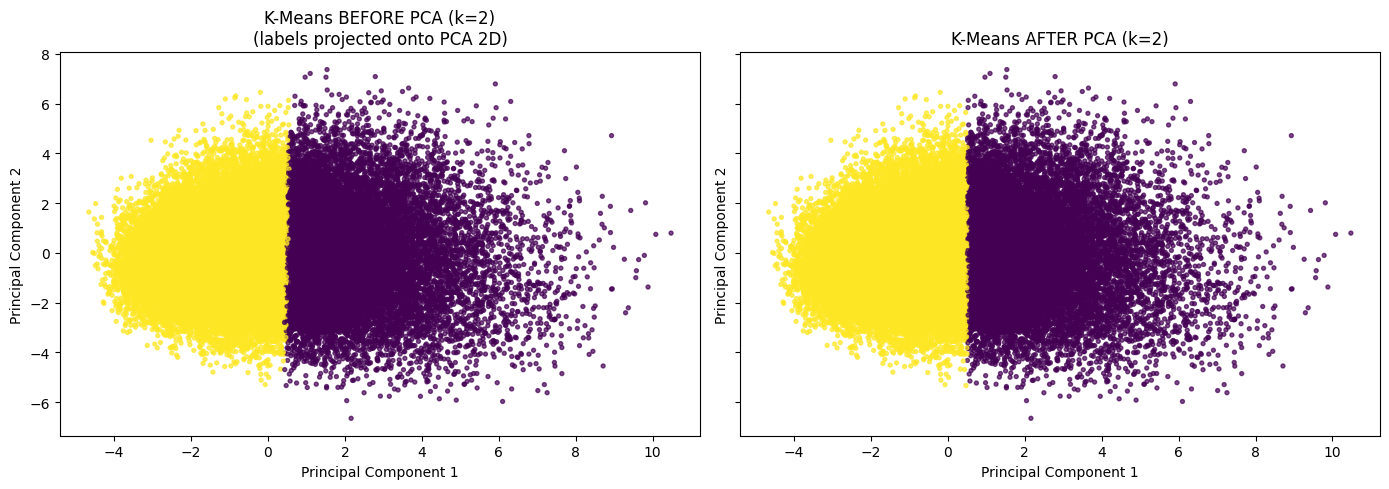

In [30]:
km2_before = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X_scaled)
km2_after  = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X_pca)

plot_compare(km2_before.labels_, km2_after.labels_, 2)

# Analysis

## 1. How did PCA affect clustering results?

PCA changed the cluster sizes and assignments (ARI = 0.457). It improved speed by 5.6× but slightly reduced clustering quality (Silhouette: 0.134 → 0.108).
## 2. Did visualization become clearer?

Yes. PCA made the clusters easier to visualize in 2D. However, the clusters still overlap, indicating weak separation.better-separated clusters.

## 3. Did you lose important information?

Yes. The first 2 components retained only 29% of the variance, meaning 71% was lost. Important features, such as bankruptcy records, were not well represented.

## 4. Which approach is better and why?

K-Means without PCA performed better because it preserved all 24 features and achieved better clustering scores. PCA was faster and easier to visualize, but reduced clustering quality.

# Bonus (Optional)

## 1. Different number of PCA components
We repeat PCA + K-Means (k = 3) with 2, 3, 5, 10 and 16 components. Every clustering is evaluated in the original 24-feature space so the numbers are comparable.

In [31]:
rows = []
for n in [2, 3, 5, 10, 16]:
    p = PCA(n_components=n, random_state=42)
    Z = p.fit_transform(X_scaled)

    t0 = time.time()
    labels_n = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z).labels_
    t = time.time() - t0

    r = evaluate(X_scaled, labels_n, f'{n} PCs')
    r['Explained variance'] = p.explained_variance_ratio_.sum()
    r['Time (s)'] = t
    rows.append(r)

pd.DataFrame(rows).set_index('Method').round(3)

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Explained variance,Time (s)
Method,,,,,
2 PCs,0.108,2.728,96901.046,0.290,5.471
3 PCs,0.109,2.699,97225.472,0.390,9.346
5 PCs,0.110,2.719,97481.347,0.546,6.945
10 PCs,0.134,2.375,103275.468,0.772,9.444
16 PCs,0.134,2.376,103280.260,0.914,20.281


## 2. Another clustering algorithm (DBSCAN)
DBSCAN groups points by density and labels isolated points as noise (-1). It does not scale to ~1M rows, so it runs on a random sample of 20,000 points in the 2-component PCA space (`eps = 0.3`, `min_samples = 10`).

In [32]:
from sklearn.cluster import DBSCAN

db_idx = np.random.RandomState(5).choice(len(X_pca), 20000, replace=False)
X_db = X_pca[db_idx]

db_labels = DBSCAN(eps=0.3, min_samples=10).fit_predict(X_db)

n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
print("Clusters found:", n_clusters)
print("Noise points  :", (db_labels == -1).sum(), f"({(db_labels == -1).mean():.1%})")
print("Cluster sizes :", pd.Series(db_labels[db_labels != -1]).value_counts().tolist())

Clusters found: 9
Noise points  : 460 (2.3%)
Cluster sizes : [19455, 20, 13, 12, 12, 10, 7, 7, 4]


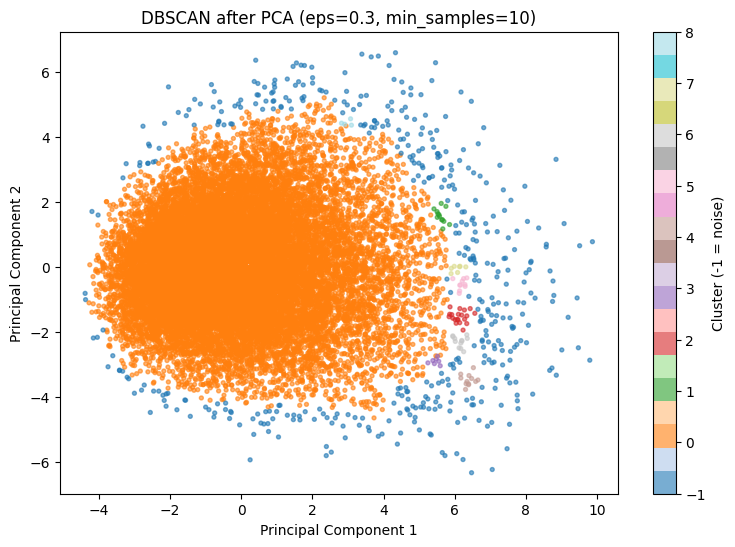

In [33]:
plt.figure(figsize=(9, 6))
plt.scatter(X_db[:, 0], X_db[:, 1], c=db_labels, cmap='tab20', s=8, alpha=0.6)
plt.title('DBSCAN after PCA (eps=0.3, min_samples=10)')
plt.xlabel('Principal Component 1'); plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster (-1 = noise)')
plt.show()



# Key Insights (Final Summary)

1. **Data Preparation:** The dataset contains 987,548 loans. After cleaning and standardization, 24 numeric features were selected.

2. **Optimal Clusters:** K = 3 was chosen, but low Silhouette scores (below 0.14) indicate weak clustering.

3. **PCA Variance:** Two PCA components retained only 29% of the variance, losing 71%.

4. **Clustering Quality:** K-Means before PCA performed better (Silhouette: 0.134 vs 0.108).

5. **2D Scores:** The higher Silhouette after PCA (0.361) reflects the 2D space and is not directly comparable to the original results.

6. **Speed and Visualization:** PCA made K-Means 5.6 times faster and improved visualization, but did not create clearly separated clusters.

7. **Cluster Changes:** PCA changed cluster assignments (ARI = 0.457) and lost some important information.

8. **Bonus Results:** Using 10 PCA components matched the original clustering quality. DBSCAN also confirmed weak cluster separation.

9. **Final Conclusion:** PCA is useful for speed and visualization, but K-Means without PCA provides better clustering quality for this dataset.